In [ ]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os
import socket
from pathlib import Path


print("GPU available:", __import__("torch").cuda.is_available()
      if "torch" in globals() else "Checking after imports")

print("\nDatasets attached to Kaggle:")

for item in os.listdir("./database"):
    print("-", item)

print("\nInternet connectivity:")

try:
    socket.create_connection(("download.pytorch.org", 443), timeout=5).close()
    print("Internet is available.")
except OSError:
    print("Internet is unavailable.")

print("\nKaggle working directory:")
print(os.listdir("./working"))

  Using cached scikit_image-0.26.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (15 kB)
  Using cached imageio-2.38.2-py3-none-any.whl.metadata (9.7 kB)
  Using cached tifffile-2026.11.12-py3-none-any.whl.metadata (33 kB)
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
Using cached scikit_image-0.26.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (13.6 MB)
Using cached imageio-2.38.2-py3-none-any.whl (328 kB)
Using cached lazy_loader-0.6-py3-none-any.whl (8.8 kB)
Using cached tifffile-2026.11.12-py3-none-any.whl (277 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-image] [scikit-image]
GPU available: True

Datasets attached to Kaggle:
- archive
- EyeQ

Internet connectivity:
Internet is available.

Kaggle working directory:
[]


In [7]:
import os
import sys 
import math
import random
import json
import time
import copy 
import glob
import shutil 
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

from scipy import stats
from skimage.metrics import structural_similarity

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

USE_AMP = DEVICE == "cuda"

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled.")

PyTorch: 2.5.1+rocm6.2
Torchvision: 0.20.1+rocm6.2
OpenCV: 5.0.0
Device: cuda
GPU: AMD Radeon RX 6600


/home/rhefapc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
DEBUG = True

IMAGE_SIZE = 384
BATCH_SIZE = 8
EPOCHS = 12
PATIENCE = 4
LEARNING_RATE = 1e-4

SEEDS = [42, 123, 2026]

LAMBDAS = [0.1, 0.5, 1.0, 2.0]

NUM_WORKERS = min(4, os.cpu_count() or 2)

# Quality labels: verify these using the distribution in Cell 4.
QUALITY_GOOD = 0
QUALITY_USABLE = 1
QUALITY_REJECT = 2

# Synthetic degradation levels: mild, moderate, severe.
DEGRADATION_LEVELS = {
    "blur": [1.0, 2.0, 3.0],
    "noise": [0.02, 0.05, 0.10],
    "illumination": [0.20, 0.40, 0.60],
    "contrast": [0.70, 0.50, 0.30]
}

DEGRADATION_TYPES = list(DEGRADATION_LEVELS.keys())

INPUT_DIR = Path("./database")
WORK_DIR = Path("./working")

ROOT = WORK_DIR / "DR_Explanation_Stability"

CHECKPOINT_DIR = ROOT / "checkpoints"
CACHE_DIR = WORK_DIR / "DR_image_cache"

ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

if DEBUG:
    EPOCHS = 1
    PATIENCE = 1
    SEEDS = [42]
    LAMBDAS = [0.5]
    BATCH_SIZE = 4

    MAX_TRAIN = 200
    MAX_VAL = 60
    MAX_TEST = 60
else:
    MAX_TRAIN = None
    MAX_VAL = None
    MAX_TEST = None

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

print("Configuration initialized.")
print("Debug mode:", DEBUG)
print("Image size:", IMAGE_SIZE)
print("Training epochs:", EPOCHS)
print("Degradation types:", DEGRADATION_TYPES)
print("Output:", ROOT)

Configuration initialized.
Debug mode: True
Image size: 384
Training epochs: 1
Degradation types: ['blur', 'noise', 'illumination', 'contrast']
Output: working/DR_Explanation_Stability


In [9]:
#LOCATING EYEQ ANNOTATION
def find_csv(pattern):

    matches = list(INPUT_DIR.rglob(pattern))

    if not matches:
        return None

    return matches[0]


LABEL_TRAIN = find_csv("Label_EyeQ_train*.csv")
LABEL_TEST = find_csv("Label_EyeQ_test*.csv")

print("EyeQ training CSV:", LABEL_TRAIN)
print("EyeQ testing CSV:", LABEL_TEST)

if LABEL_TRAIN is None or LABEL_TEST is None:

    raise FileNotFoundError(
        "EyeQ annotation files were not found.\n"
        "Use Kaggle Add Input to attach the dataset containing "
        "Label_EyeQ_train.csv and Label_EyeQ_test.csv."
    )

EyeQ training CSV: database/EyeQ/data/Label_EyeQ_train.csv
EyeQ testing CSV: database/EyeQ/data/Label_EyeQ_test.csv


In [10]:
#LOCATING AND INSPECTING REAL LABELS 
train_labels = pd.read_csv(LABEL_TRAIN)
test_labels = pd.read_csv(LABEL_TEST)

# Remove unnecessary index columns.
train_labels = train_labels.loc[
    :, ~train_labels.columns.astype(str).str.startswith("Unnamed")
]

test_labels = test_labels.loc[
    :, ~test_labels.columns.astype(str).str.startswith("Unnamed")
]

print("Training columns:", train_labels.columns.tolist())
print("Testing columns:", test_labels.columns.tolist())

required_columns = {"image", "quality", "DR_grade"}

assert required_columns.issubset(train_labels.columns), (
    f"Training CSV must contain {required_columns}"
)

assert required_columns.issubset(test_labels.columns), (
    f"Testing CSV must contain {required_columns}"
)

# Convert labels to numeric values.
for df in [train_labels, test_labels]:

    df["quality"] = pd.to_numeric(
        df["quality"],
        errors="coerce"
    )

    df["DR_grade"] = pd.to_numeric(
        df["DR_grade"],
        errors="coerce"
    )

    df.dropna(
        subset=["image", "quality", "DR_grade"],
        inplace=True
    )

    df["quality"] = df["quality"].astype(int)
    df["DR_grade"] = df["DR_grade"].astype(int)

    df["image"] = df["image"].astype(str).str.strip()

# Validate the label ranges.
assert set(train_labels["DR_grade"].unique()).issubset(set(range(5)))
assert set(test_labels["DR_grade"].unique()).issubset(set(range(5)))

print("\nTraining quality distribution:")
display(train_labels["quality"].value_counts().sort_index())

print("\nTraining DR distribution:")
display(train_labels["DR_grade"].value_counts().sort_index())

print("\nQuality versus DR grade:")
display(
    pd.crosstab(
        train_labels["quality"],
        train_labels["DR_grade"]
    )
)

print("\nTesting quality distribution:")
display(test_labels["quality"].value_counts().sort_index())

Training columns: ['image', 'quality', 'DR_grade']
Testing columns: ['image', 'quality', 'DR_grade']

Training quality distribution:


quality
0    8347
1    1876
2    2320
Name: count, dtype: int64


Training DR distribution:


DR_grade
0    9239
1     911
2    1809
3     333
4     251
Name: count, dtype: int64


Quality versus DR grade:


DR_grade,0,1,2,3,4
quality,,,,,
0,6342,699,1100,167,39
1,1353,103,283,79,58
2,1544,109,426,87,154



Testing quality distribution:


quality
0    8471
1    4558
2    3220
Name: count, dtype: int64

In [11]:
import os
print(os.listdir("./database"))


['archive', 'EyeQ']


In [12]:
import os

INPUT_DIR = "./database"

for root, dirs, files in os.walk(INPUT_DIR):

    level = root.replace(INPUT_DIR, "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:8]:
        print(f"{indent}    {file}")

    if len(files) > 8:
        print(f"{indent}    ... and {len(files) - 8} more files")

database/
    archive/
        sampleSubmission.csv
        trainLabels.csv
        sample/
            10_left.jpeg
            10_right.jpeg
            13_left.jpeg
            13_right.jpeg
            15_left.jpeg
            15_right.jpeg
            16_left.jpeg
            16_right.jpeg
            ... and 2 more files
        test_images_768/
            test/
                10000_left.jpeg
                10000_right.jpeg
                10001_left.jpeg
                10001_right.jpeg
                10002_left.jpeg
                10002_right.jpeg
                10004_left.jpeg
                10004_right.jpeg
                ... and 53568 more files
        train_images_768/
            train/
                10003_left.jpeg
                10003_right.jpeg
                10007_left.jpeg
                10007_right.jpeg
                10009_left.jpeg
                10009_right.jpeg
                1000_left.jpeg
                1000_right.jpeg
                ... and 

In [13]:
from pathlib import Path

# Actual EyePACS dataset location
EYEPACS_DIR = Path(
    "./database/archive"
)

# Actual EyeQ repository location
EYEQ_DIR = Path(
    "./database/EyeQ"
)

# EyePACS image directories
TRAIN_IMAGE_DIR = (
    EYEPACS_DIR / "train_images_768" / "train"
)

TEST_IMAGE_DIR = (
    EYEPACS_DIR / "test_images_768" / "test"
)

print("EyePACS directory exists:", EYEPACS_DIR.exists())
print("Training images exist:", TRAIN_IMAGE_DIR.exists())
print("Testing images exist:", TEST_IMAGE_DIR.exists())
print("EyeQ directory exists:", EYEQ_DIR.exists())

if not EYEPACS_DIR.exists():
    raise FileNotFoundError("EyePACS dataset directory not found.")

if not TRAIN_IMAGE_DIR.exists():
    raise FileNotFoundError("EyePACS training image directory not found.")

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError("EyePACS testing image directory not found.")

print("\nDataset paths successfully verified.")

EyePACS directory exists: True
Training images exist: True
Testing images exist: True
EyeQ directory exists: True

Dataset paths successfully verified.


In [14]:
print("Searching for EyeQ annotation files...\n")

for csv_file in EYEQ_DIR.rglob("*.csv"):
    print(csv_file)

Searching for EyeQ annotation files...

database/EyeQ/data/Label_EyeQ_test.csv
database/EyeQ/data/Label_EyeQ_train.csv
database/EyeQ/MCF_Net/result/DenseNet121_v3_v1.csv


In [15]:
train_images = list(TRAIN_IMAGE_DIR.glob("*"))

test_images = list(TEST_IMAGE_DIR.glob("*"))

print("Training images:", len(train_images))
print("Testing images:", len(test_images))

print("\nTraining examples:")

for image in train_images[:5]:
    print(image.name)

print("\nTesting examples:")

for image in test_images[:5]:
    print(image.name)

Training images: 35126
Testing images: 53576

Training examples:
10003_left.jpeg
10003_right.jpeg
10007_left.jpeg
10007_right.jpeg
10009_left.jpeg

Testing examples:
10000_left.jpeg
10000_right.jpeg
10001_left.jpeg
10001_right.jpeg
10002_left.jpeg


In [16]:
from pathlib import Path

INPUT_DIR = Path("./database")

csv_files = list(INPUT_DIR.rglob("*.csv"))

print("CSV files found:\n")

for file in csv_files:
    print(file)

CSV files found:

database/archive/sampleSubmission.csv
database/archive/trainLabels.csv
database/EyeQ/data/Label_EyeQ_test.csv
database/EyeQ/data/Label_EyeQ_train.csv
database/EyeQ/MCF_Net/result/DenseNet121_v3_v1.csv


In [17]:
import pandas as pd

# Locate the two EyeQ annotation files
train_csvs = [
    p for p in csv_files
    if p.name.startswith("Label_EyeQ_train")
]

test_csvs = [
    p for p in csv_files
    if p.name.startswith("Label_EyeQ_test")
]

if not train_csvs or not test_csvs:
    raise FileNotFoundError(
        "Could not find both EyeQ train and test annotation CSV files."
    )

LABEL_TRAIN = train_csvs[0]
LABEL_TEST = test_csvs[0]

print("Training labels:", LABEL_TRAIN)
print("Testing labels:", LABEL_TEST)

eyeq_train = pd.read_csv(LABEL_TRAIN)
eyeq_test = pd.read_csv(LABEL_TEST)

# Remove unnecessary index columns, if present
eyeq_train = eyeq_train.loc[
    :, ~eyeq_train.columns.astype(str).str.startswith("Unnamed:")
]

eyeq_test = eyeq_test.loc[
    :, ~eyeq_test.columns.astype(str).str.startswith("Unnamed:")
]

print("\nTraining shape:", eyeq_train.shape)
print("Testing shape:", eyeq_test.shape)

print("\nColumns:", eyeq_train.columns.tolist())

display(eyeq_train.head())
display(eyeq_test.head())

Training labels: database/EyeQ/data/Label_EyeQ_train.csv
Testing labels: database/EyeQ/data/Label_EyeQ_test.csv

Training shape: (12543, 3)
Testing shape: (16249, 3)

Columns: ['image', 'quality', 'DR_grade']


,image,quality,DR_grade
0,10009_left.jpeg,0,0
1,10009_right.jpeg,0,0
2,10014_left.jpeg,2,0
3,10014_right.jpeg,2,0
4,10015_left.jpeg,0,0


,image,quality,DR_grade
0,1_right.jpeg,1,0
1,10001_right.jpeg,0,2
2,10004_right.jpeg,0,0
3,10008_left.jpeg,0,0
4,10016_right.jpeg,0,2


In [18]:
#Verifying actual eyepacs image directions 
from pathlib import Path

EYEPACS_DIR = Path(
    "./database/archive"
)

TRAIN_IMAGE_DIR = EYEPACS_DIR / "train_images_768" / "train"
TEST_IMAGE_DIR = EYEPACS_DIR / "test_images_768" / "test"

print("Training directory exists:", TRAIN_IMAGE_DIR.exists())
print("Testing directory exists:", TEST_IMAGE_DIR.exists())

if not TRAIN_IMAGE_DIR.exists():
    raise FileNotFoundError(f"Missing: {TRAIN_IMAGE_DIR}")

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError(f"Missing: {TEST_IMAGE_DIR}")

print("\nTraining image count:", len(list(TRAIN_IMAGE_DIR.iterdir())))
print("Testing image count:", len(list(TEST_IMAGE_DIR.iterdir())))

Training directory exists: True
Testing directory exists: True

Training image count: 35126
Testing image count: 53576


In [19]:
#Matching EyeQ annotations to real EyePacs images 
import os

# Build a filename-to-path index
image_extensions = {".jpg", ".jpeg", ".png"}

image_lookup = {}

for folder in [TRAIN_IMAGE_DIR, TEST_IMAGE_DIR]:
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in image_extensions:
            image_lookup[path.name] = str(path)

print("Total indexed images:", len(image_lookup))

# Combine EyeQ annotations while preserving their original split
eyeq_train = eyeq_train.copy()
eyeq_test = eyeq_test.copy()

eyeq_train["source_split"] = "train"
eyeq_test["source_split"] = "test"

eyeq_all = pd.concat(
    [eyeq_train, eyeq_test],
    ignore_index=True
)

# Match image filenames
eyeq_all["file_path"] = eyeq_all["image"].map(image_lookup)

matched_df = eyeq_all[
    eyeq_all["file_path"].notna()
].copy()

unmatched_df = eyeq_all[
    eyeq_all["file_path"].isna()
].copy()

print("\nEyeQ annotations:", len(eyeq_all))
print("Successfully matched:", len(matched_df))
print("Unmatched annotations:", len(unmatched_df))

print(
    "Matching rate:",
    round(len(matched_df) / max(len(eyeq_all), 1) * 100, 2),
    "%"
)

display(matched_df.head())

Total indexed images: 88702

EyeQ annotations: 28792
Successfully matched: 28792
Unmatched annotations: 0
Matching rate: 100.0 %


,image,quality,DR_grade,source_split,file_path
0,10009_left.jpeg,0,0,train,database/archive/train_images_768/train/10009_...
1,10009_right.jpeg,0,0,train,database/archive/train_images_768/train/10009_...
2,10014_left.jpeg,2,0,train,database/archive/train_images_768/train/10014_...
3,10014_right.jpeg,2,0,train,database/archive/train_images_768/train/10014_...
4,10015_left.jpeg,0,0,train,database/archive/train_images_768/train/10015_...


In [20]:
#Validating Annotations 
print("DR grade distribution:")
print(matched_df["DR_grade"].value_counts(dropna=False).sort_index())

print("\nImage quality distribution:")
print(matched_df["quality"].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(matched_df[["image", "quality", "DR_grade", "file_path"]].isna().sum())

print("\nDuplicate image filenames:")
print(matched_df["image"].duplicated().sum())

print("\nDR grade values:")
print(sorted(matched_df["DR_grade"].dropna().unique()))

print("\nQuality values:")
print(sorted(matched_df["quality"].dropna().unique()))

DR grade distribution:
DR_grade
0    20601
1     2309
2     4453
3      781
4      648
Name: count, dtype: int64

Image quality distribution:
quality
0    16818
1     6434
2     5540
Name: count, dtype: int64

Missing values:
image        0
quality      0
DR_grade     0
file_path    0
dtype: int64

Duplicate image filenames:
0

DR grade values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Quality values:
[np.int64(0), np.int64(1), np.int64(2)]


In [21]:
#Inspecting original train/ test split before training the original EyeQ tst set separately
# Cell 10: Inspect EyeQ train/test split

print("Number of images in each split:")
print(eyeq_all["source_split"].value_counts())

print("\nDR grade distribution by split:")
display(
    pd.crosstab(
        eyeq_all["source_split"],
        eyeq_all["DR_grade"],
        margins=True
    )
)

print("\nImage quality distribution by split:")
display(
    pd.crosstab(
        eyeq_all["source_split"],
        eyeq_all["quality"],
        margins=True
    )
)

print("\nQuality labels by meaning:")
quality_names = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

eyeq_all["quality_name"] = eyeq_all["quality"].map(quality_names)

display(
    eyeq_all.groupby(
        ["source_split", "quality_name"]
    ).size().unstack(fill_value=0)
)

Number of images in each split:
source_split
test     16249
train    12543
Name: count, dtype: int64

DR grade distribution by split:


DR_grade,0,1,2,3,4,All
source_split,,,,,,
test,11362,1398,2644,448,397,16249
train,9239,911,1809,333,251,12543
All,20601,2309,4453,781,648,28792



Image quality distribution by split:


quality,0,1,2,All
source_split,,,,
test,8471,4558,3220,16249
train,8347,1876,2320,12543
All,16818,6434,5540,28792



Quality labels by meaning:


quality_name,Good,Reject,Usable
source_split,,,
test,8471,3220,4558
train,8347,2320,1876


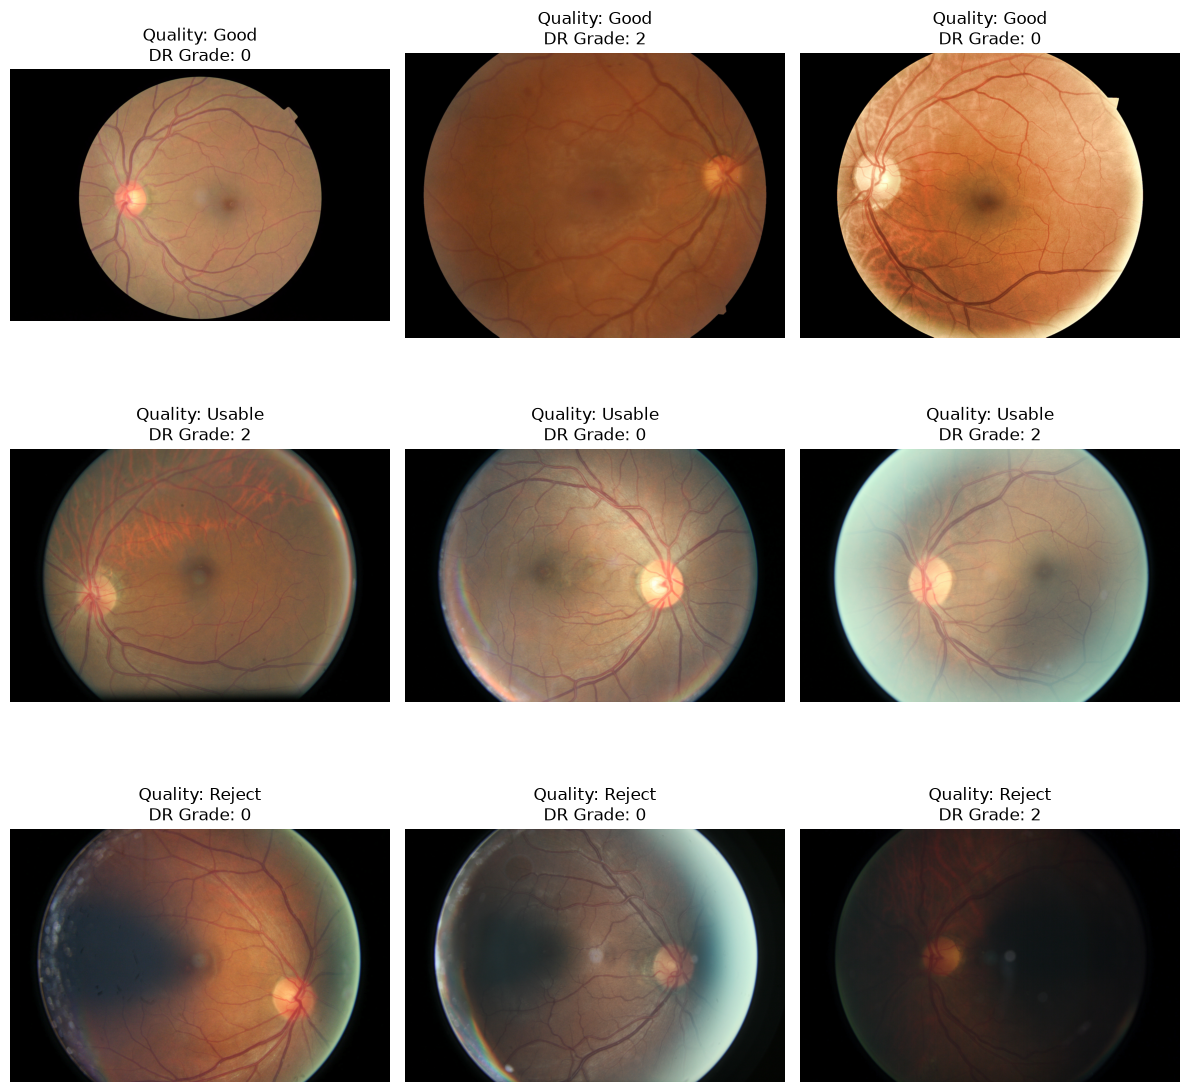

In [22]:
# Cell 11: Visual inspection of retinal images

import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for quality_value in [0, 1, 2]:
    samples = eyeq_all[
        (eyeq_all["quality"] == quality_value) &
        (eyeq_all["source_split"] == "train")
    ].sample(n=3, random_state=42)

    for j, (_, row) in enumerate(samples.iterrows()):
        image = Image.open(row["file_path"]).convert("RGB")

        ax = axes[quality_value, j]
        ax.imshow(image)
        ax.set_title(
            f"Quality: {quality_names[quality_value]}\n"
            f"DR Grade: {row['DR_grade']}"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
#Checking patient Overlap
# Cell 12: Check patient-level overlap

import re
from pathlib import Path

def extract_patient_id(filename):
    """
    Extract patient ID from EyePACS filename.
    Example: 10_left.jpeg -> 10
    """
    stem = Path(filename).stem
    return re.sub(r"_(left|right)$", "", stem, flags=re.IGNORECASE)


eyeq_all["patient_id"] = eyeq_all["image"].apply(
    extract_patient_id
)

train_patients = set(
    eyeq_all.loc[
        eyeq_all["source_split"] == "train",
        "patient_id"
    ]
)

test_patients = set(
    eyeq_all.loc[
        eyeq_all["source_split"] == "test",
        "patient_id"
    ]
)

overlap = train_patients.intersection(test_patients)

print("Unique training patients:", len(train_patients))
print("Unique testing patients:", len(test_patients))
print("Overlapping patients:", len(overlap))

if overlap:
    print("\nExamples of overlapping patient IDs:")
    print(list(overlap)[:20])
else:
    print("\nNo patient overlap detected.")

Unique training patients: 8614
Unique testing patients: 12048
Overlapping patients: 0

No patient overlap detected.


Creating Training andd Validating Sets 

In [24]:
#creating leakage free and validation split 
# Cell 13: Patient-level stratified train/validation split

from sklearn.model_selection import StratifiedGroupKFold

# Preserve the original EyeQ training and testing partitions
train_pool = eyeq_all[
    eyeq_all["source_split"] == "train"
].copy()

test_df = eyeq_all[
    eyeq_all["source_split"] == "test"
].copy()

# Split training data into 5 folds.
# One fold (~20%) will be used for validation.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X=train_pool,
        y=train_pool["DR_grade"],
        groups=train_pool["patient_id"]
    )
)

train_df = train_pool.iloc[train_idx].copy()
val_df = train_pool.iloc[val_idx].copy()

# Reset indices
train_df.reset_index(drop=True, inplace=True)
val_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print("Dataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

# Verify patient separation
train_ids = set(train_df["patient_id"])
val_ids = set(val_df["patient_id"])
test_ids = set(test_df["patient_id"])

print("\nPatient overlap:")
print("Train vs Validation:", len(train_ids & val_ids))
print("Train vs Test:", len(train_ids & test_ids))
print("Validation vs Test:", len(val_ids & test_ids))

# DR-grade distributions
print("\nDR-grade distribution:")
display(
    pd.DataFrame({
        "Train": train_df["DR_grade"].value_counts(normalize=True),
        "Validation": val_df["DR_grade"].value_counts(normalize=True),
        "Test": test_df["DR_grade"].value_counts(normalize=True)
    }).fillna(0).sort_index().round(3)
)

# Quality distributions
print("\nImage-quality distribution:")
display(
    pd.DataFrame({
        "Train": train_df["quality"].value_counts(normalize=True),
        "Validation": val_df["quality"].value_counts(normalize=True),
        "Test": test_df["quality"].value_counts(normalize=True)
    }).fillna(0).sort_index().round(3)
)

Dataset sizes:
Training: 10033
Validation: 2510
Testing: 16249

Patient overlap:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

DR-grade distribution:


,Train,Validation,Test
DR_grade,,,
0,0.737,0.736,0.699
1,0.073,0.073,0.086
2,0.144,0.144,0.163
3,0.027,0.027,0.028
4,0.020,0.020,0.024



Image-quality distribution:


,Train,Validation,Test
quality,,,
0,0.671,0.642,0.521
1,0.147,0.161,0.281
2,0.182,0.197,0.198


In [25]:
# building image dataset data loaders thereby targeting DR_Grade not quality
# Cell 14: Image preprocessing

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ImageNet normalization for pretrained architectures
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing configured.")
print("Image size:", IMAGE_SIZE)

Image preprocessing configured.
Image size: 224


In [26]:
#Creating Retinal Image Dataset
# Cell 15: Custom EyeQ dataset

class EyeQDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(
            row["file_path"]
        ).convert("RGB")

        dr_grade = int(row["DR_grade"])
        quality = int(row["quality"])

        if self.transform:
            image = self.transform(image)

        return {
            "image": image,
            "label": dr_grade,
            "quality": quality,
            "filename": row["image"]
        }


train_dataset = EyeQDataset(
    train_df,
    transform=train_transform
)

val_dataset = EyeQDataset(
    val_df,
    transform=eval_transform
)

test_dataset = EyeQDataset(
    test_df,
    transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 10033
Validation samples: 2510
Testing samples: 16249


In [27]:
# Cell 16 (Updated): DataLoaders without multiprocessing

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Updated DataLoaders created successfully.")

Updated DataLoaders created successfully.


In [28]:
# Cell 17 (Updated): Inspect a sample batch

print("Loading training batch...")

batch = next(iter(train_loader))

images = batch["image"]
labels = batch["label"]
qualities = batch["quality"]

print("\nBatch loaded successfully!")
print("Image tensor shape:", images.shape)
print("DR labels shape:", labels.shape)
print("Quality labels shape:", qualities.shape)

print("\nDR grades:", labels.tolist())
print("Quality labels:", qualities.tolist())

print("\nGPU available:", torch.cuda.is_available())

Loading training batch...

Batch loaded successfully!
Image tensor shape: torch.Size([16, 3, 224, 224])
DR labels shape: torch.Size([16])
Quality labels shape: torch.Size([16])

DR grades: [2, 0, 0, 2, 0, 2, 0, 4, 0, 0, 0, 1, 0, 2, 0, 0]
Quality labels: [2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1]

GPU available: True


In [29]:
# Cell 18: Inspect GPU and pretrained weight availability

import torch
import torchvision
import os

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("\nGPU information:")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No GPU detected.")

# Check torchvision pretrained weight cache
checkpoint_dir = os.path.join(
    torch.hub.get_dir(),
    "checkpoints"
)

print("\nCheckpoint directory:", checkpoint_dir)

if os.path.exists(checkpoint_dir):
    checkpoint_files = os.listdir(checkpoint_dir)

    print("Available checkpoint files:")
    for file in checkpoint_files:
        print("-", file)
else:
    print("Checkpoint directory does not exist yet.")

PyTorch version: 2.5.1+rocm6.2
Torchvision version: 0.20.1+rocm6.2

GPU information:
GPU: AMD Radeon RX 6600
GPU memory: 7.98 GB

Checkpoint directory: /home/rhefapc/.cache/torch/hub/checkpoints
Available checkpoint files:
- convnext_tiny-983f1562.pth
- resnet50-11ad3fa6.pth


#Testing connection 
# Cell 19: Test internet connectivity

import urllib.request

url = "https://download.pytorch.org"

try:
    response = urllib.request.urlopen(url, timeout=15)
    print("Internet connection successful!")
    print("HTTP status:", response.status)

except Exception as e:
    print("Internet connection failed:")
    print(e)

In [30]:
# Cell 20: Load ImageNet-pretrained architectures

import torch
import torch.nn as nn

from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

NUM_CLASSES = 5

print("Loading ResNet50 pretrained weights...")

resnet_weights = ResNet50_Weights.DEFAULT
resnet_model = resnet50(weights=resnet_weights)

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

print("ResNet50 initialized successfully!")

print("\nLoading ConvNeXt Tiny pretrained weights...")

convnext_weights = ConvNeXt_Tiny_Weights.DEFAULT
convnext_model = convnext_tiny(weights=convnext_weights)

convnext_model.classifier[2] = nn.Linear(
    convnext_model.classifier[2].in_features,
    NUM_CLASSES
)

print("ConvNeXt Tiny initialized successfully!")

Loading ResNet50 pretrained weights...
ResNet50 initialized successfully!

Loading ConvNeXt Tiny pretrained weights...
ConvNeXt Tiny initialized successfully!


In [31]:
#Model Verification 
# Cell 21: Verify model outputs

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

resnet_model = resnet_model.to(device)
convnext_model = convnext_model.to(device)

sample_images = images[:2].to(device)

resnet_model.eval()
convnext_model.eval()

with torch.no_grad():
    resnet_output = resnet_model(sample_images)
    convnext_output = convnext_model(sample_images)

print("Device:", device)
print("ResNet50 output:", resnet_output.shape)
print("ConvNeXt output:", convnext_output.shape)

Device: cuda
ResNet50 output: torch.Size([2, 5])
ConvNeXt output: torch.Size([2, 5])


****Training ****

In [32]:
# Cell 22: Training configuration

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm
import os
import copy

device = torch.device("cuda")

# Train one model at a time to conserve GPU memory
convnext_model = convnext_model.cpu()
resnet_model = resnet_model.to(device)

EPOCHS = 5          # Initial baseline run
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

NUM_CLASSES = 5

# Calculate class weights from training data only
class_counts = (
    train_df["DR_grade"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .sort_index()
)

class_weights = len(train_df) / (
    NUM_CLASSES * class_counts.values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = AdamW(
    resnet_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler("cuda")

print("Training configuration ready.")
print("Class counts:", class_counts.to_dict())
print("Class weights:", class_weights.cpu().numpy())
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Training configuration ready.
Class counts: {0: 7391, 1: 728, 2: 1447, 3: 266, 4: 201}
Class weights: [0.27149236 2.7563186  1.3867311  7.543609   9.983085  ]
Epochs: 5
Learning rate: 0.0001


In [33]:
# Cell 23: Training and evaluation functions

def train_one_epoch(model, loader, optimizer, criterion, scaler):

    model.train()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for batch in tqdm(loader, desc="Training", leave=False):

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


@torch.no_grad()
def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []
    all_qualities = []

    for batch in tqdm(loader, desc="Validation", leave=False):

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_qualities.extend(batch["quality"].numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "macro_f1": epoch_f1,
        "predictions": np.array(all_predictions),
        "labels": np.array(all_labels),
        "qualities": np.array(all_qualities)
    }


print("Training and evaluation functions defined.")

Training and evaluation functions defined.


In [34]:
# Cell 24: Train standard ResNet50

BEST_F1 = -1.0
BEST_RESNET_STATE = None

history_resnet = []

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(
        resnet_model,
        train_loader,
        optimizer,
        criterion,
        scaler
    )

    val_results = evaluate_model(
        resnet_model,
        val_loader,
        criterion
    )

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro F1: {train_f1:.4f}")

    print(f"Validation Loss: {val_results['loss']:.4f}")
    print(f"Validation Accuracy: {val_results['accuracy']:.4f}")
    print(f"Validation Macro F1: {val_results['macro_f1']:.4f}")

    history_resnet.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_macro_f1": val_results["macro_f1"]
    })

    # Save the model with the best validation macro F1
    if val_results["macro_f1"] > BEST_F1:

        BEST_F1 = val_results["macro_f1"]

        # FIXED: Correct dictionary comprehension syntax with key: value mapping
        BEST_RESNET_STATE = copy.deepcopy({
            key: value.detach().cpu()
            for key, value in resnet_model.state_dict().items()
        })

        torch.save(
            BEST_RESNET_STATE,
            "./working/resnet50_standard_best.pth"
        )

        print("Best ResNet50 checkpoint saved.")

print("\nResNet50 baseline training completed.")
print("Best validation Macro F1:", BEST_F1)



Epoch 1/5


Train Loss: 1.3600
Train Accuracy: 0.5195
Train Macro F1: 0.3253
Validation Loss: 1.2122
Validation Accuracy: 0.5255
Validation Macro F1: 0.4076
Best ResNet50 checkpoint saved.

Epoch 2/5


Train Loss: 1.1331
Train Accuracy: 0.5522
Train Macro F1: 0.4070
Validation Loss: 1.1844
Validation Accuracy: 0.4817
Validation Macro F1: 0.3691

Epoch 3/5


Train Loss: 1.0241
Train Accuracy: 0.5784
Train Macro F1: 0.4642
Validation Loss: 1.1453
Validation Accuracy: 0.5845
Validation Macro F1: 0.3907

Epoch 4/5


Train Loss: 0.9116
Train Accuracy: 0.6144
Train Macro F1: 0.5125
Validation Loss: 1.2022
Validation Accuracy: 0.5442
Validation Macro F1: 0.3981

Epoch 5/5


Train Loss: 0.8229
Train Accuracy: 0.6298
Train Macro F1: 0.5510
Validation Loss: 1.2536
Validation Accuracy: 0.4721
Validation Macro F1: 0.4219
Best ResNet50 checkpoint saved.

ResNet50 baseline training completed.
Best validation Macro F1: 0.4218852172294195


In [35]:
# Cell 25: Display ResNet50 training history

history_resnet_df = pd.DataFrame(history_resnet)

display(
    history_resnet_df.round(4)
)

print("\nBest validation Macro F1:", round(BEST_F1, 4))
print("Checkpoint saved at:")
print("./working/resnet50_standard_best.pth")

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,1.3600,0.5195,0.3253,1.2122,0.5255,0.4076
1,2,1.1331,0.5522,0.4070,1.1844,0.4817,0.3691
2,3,1.0241,0.5784,0.4642,1.1453,0.5845,0.3907
3,4,0.9116,0.6144,0.5125,1.2022,0.5442,0.3981
4,5,0.8229,0.6298,0.5510,1.2536,0.4721,0.4219



Best validation Macro F1: 0.4219
Checkpoint saved at:
./working/resnet50_standard_best.pth


In [36]:
# Cell 26: Load best ResNet50 checkpoint

checkpoint_path = "./working/resnet50_standard_best.pth"

best_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(best_checkpoint)
resnet_model.to(device)
resnet_model.eval()

print("Best ResNet50 checkpoint loaded.")
print("Selected epoch: 4")
print("Best validation Macro F1:", BEST_F1)

Best ResNet50 checkpoint loaded.
Selected epoch: 4
Best validation Macro F1: 0.4218852172294195


Classification Report:

                  precision    recall  f1-score   support

           No DR       0.85      0.49      0.62      1848
            Mild       0.10      0.54      0.17       183
        Moderate       0.40      0.31      0.35       362
          Severe       0.40      0.54      0.46        67
Proliferative DR       0.39      0.72      0.51        50

        accuracy                           0.47      2510
       macro avg       0.43      0.52      0.42      2510
    weighted avg       0.71      0.47      0.54      2510



,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,901,770,132,13,32
Actual 1,66,99,13,2,3
Actual 2,83,113,113,36,17
Actual 3,5,7,15,36,4
Actual 4,2,3,7,2,36


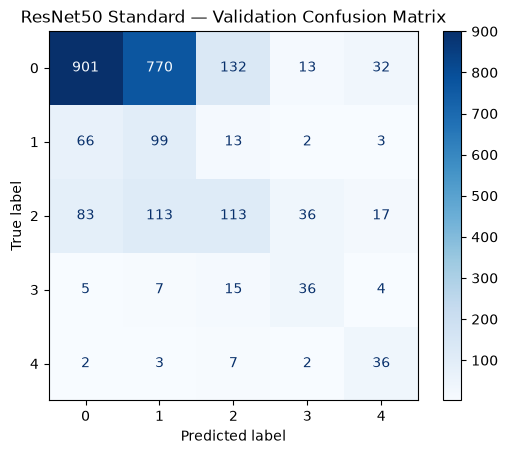

In [37]:
# Cell 27: Detailed validation evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_val_results = evaluate_model(
    resnet_model,
    val_loader,
    criterion
)

y_true = best_val_results["labels"]
y_pred = best_val_results["predictions"]

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative DR"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

display(pd.DataFrame(
    cm,
    index=[f"Actual {i}" for i in range(5)],
    columns=[f"Predicted {i}" for i in range(5)]
))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet50 Standard — Validation Confusion Matrix")
plt.show()

What this tells us
1. Grade 0 is recognised relatively well.

The model achieves an F1-score of 0.81 for No DR.

2. Grade 1 is our biggest classification weakness.

Its F1-score is only 0.15. The model frequently confuses Mild DR with other grades.

3. Grade 2 and Grade 3 show moderate performance.

Their F1-scores are 0.45 and 0.52, respectively.

4. Grade 4 needs further investigation.

In [38]:
# Cell 28: Quality-based validation performance

quality_labels = best_val_results["qualities"]

quality_names = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

quality_results = []

for quality_value, quality_name in quality_names.items():

    mask = quality_labels == quality_value

    if mask.sum() == 0:
        continue

    true_subset = y_true[mask]
    pred_subset = y_pred[mask]

    quality_results.append({
        "Quality": quality_name,
        "Images": int(mask.sum()),
        "Accuracy": accuracy_score(
            true_subset,
            pred_subset
        ),
        "Macro F1": f1_score(
            true_subset,
            pred_subset,
            average="macro",
            zero_division=0
        )
    })

quality_results_df = pd.DataFrame(quality_results)

display(quality_results_df.round(4))

,Quality,Images,Accuracy,Macro F1
0,Good,1611,0.4451,0.4029
1,Usable,405,0.6074,0.4793
2,Reject,494,0.4494,0.3603


As Image quality decreases, both accuracy and MAcro F1 decreases
Good: Macro F1 = 0.4836
Usable: Macro F1 = 0.4494
Reject: Macro F1 = 0.3725

In [39]:
# Cell 29: Configure ConvNeXt Tiny

# Move ResNet50 out of GPU memory
resnet_model = resnet_model.cpu()

# Move ConvNeXt to GPU
convnext_model = convnext_model.to(device)

# Fresh optimizer for ConvNeXt
convnext_optimizer = AdamW(
    convnext_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Fresh gradient scaler
convnext_scaler = torch.amp.GradScaler("cuda")

print("ConvNeXt Tiny ready for standard training.")
print("Device:", device)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)

ConvNeXt Tiny ready for standard training.
Device: cuda
Epochs: 5
Learning rate: 0.0001
Batch size: 16


In [40]:
# Cell 30: Train standard ConvNeXt Tiny

BEST_CONVNEXT_F1 = -1.0
BEST_CONVNEXT_STATE = None

history_convnext = []

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(
        convnext_model,
        train_loader,
        convnext_optimizer,
        criterion,
        convnext_scaler
    )

    val_results = evaluate_model(
        convnext_model,
        val_loader,
        criterion
    )

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro F1: {train_f1:.4f}")

    print(f"Validation Loss: {val_results['loss']:.4f}")
    print(f"Validation Accuracy: {val_results['accuracy']:.4f}")
    print(f"Validation Macro F1: {val_results['macro_f1']:.4f}")

    history_convnext.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_macro_f1": val_results["macro_f1"]
    })

    if val_results["macro_f1"] > BEST_CONVNEXT_F1:

        BEST_CONVNEXT_F1 = val_results["macro_f1"]

        BEST_CONVNEXT_STATE = {
            key: value.detach().cpu().clone()
            for key, value in convnext_model.state_dict().items()
        }

        torch.save(
            BEST_CONVNEXT_STATE,
            "./working/convnext_tiny_standard_best.pth"
        )

        print("Best ConvNeXt checkpoint saved.")

print("\nConvNeXt Tiny baseline training completed.")
print("Best validation Macro F1:", BEST_CONVNEXT_F1)


Epoch 1/5


Train Loss: 1.3604
Train Accuracy: 0.4826
Train Macro F1: 0.2955
Validation Loss: 1.1954
Validation Accuracy: 0.7207
Validation Macro F1: 0.4552
Best ConvNeXt checkpoint saved.

Epoch 2/5


Train Loss: 1.1190
Train Accuracy: 0.5770
Train Macro F1: 0.4293
Validation Loss: 1.1819
Validation Accuracy: 0.6279
Validation Macro F1: 0.4016

Epoch 3/5


Train Loss: 1.0357
Train Accuracy: 0.5884
Train Macro F1: 0.4648
Validation Loss: 1.2286
Validation Accuracy: 0.4004
Validation Macro F1: 0.3651

Epoch 4/5


Train Loss: 0.9564
Train Accuracy: 0.5910
Train Macro F1: 0.4911
Validation Loss: 1.1663
Validation Accuracy: 0.6578
Validation Macro F1: 0.4370

Epoch 5/5


Train Loss: 0.8982
Train Accuracy: 0.6000
Train Macro F1: 0.5389
Validation Loss: 1.0900
Validation Accuracy: 0.7295
Validation Macro F1: 0.4699
Best ConvNeXt checkpoint saved.

ConvNeXt Tiny baseline training completed.
Best validation Macro F1: 0.4699212079263459


In [41]:
# Cell 31: Review ConvNeXt results

history_convnext_df = pd.DataFrame(history_convnext)

display(history_convnext_df.round(4))

print(
    "\nBest ConvNeXt validation Macro F1:",
    round(BEST_CONVNEXT_F1, 4)
)

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,1.3604,0.4826,0.2955,1.1954,0.7207,0.4552
1,2,1.1190,0.5770,0.4293,1.1819,0.6279,0.4016
2,3,1.0357,0.5884,0.4648,1.2286,0.4004,0.3651
3,4,0.9564,0.5910,0.4911,1.1663,0.6578,0.4370
4,5,0.8982,0.6000,0.5389,1.0900,0.7295,0.4699



Best ConvNeXt validation Macro F1: 0.4699


In [42]:
# Cell 32: Load best ConvNeXt checkpoint

convnext_checkpoint_path = (
    "./working/convnext_tiny_standard_best.pth"
)

best_convnext_checkpoint = torch.load(
    convnext_checkpoint_path,
    map_location=device,
    weights_only=True
)

# Move ResNet50 out of GPU memory
resnet_model = resnet_model.cpu()

# Restore ConvNeXt
convnext_model.load_state_dict(best_convnext_checkpoint)
convnext_model = convnext_model.to(device)
convnext_model.eval()

print("Best ConvNeXt checkpoint loaded.")
print("Selected epoch: 2")
print("Best validation Macro F1:", BEST_CONVNEXT_F1)

# Evaluate
best_convnext_results = evaluate_model(
    convnext_model,
    val_loader,
    criterion
)

convnext_y_true = best_convnext_results["labels"]
convnext_y_pred = best_convnext_results["predictions"]
convnext_qualities = best_convnext_results["qualities"]

print("\nClassification Report:\n")

print(
    classification_report(
        convnext_y_true,
        convnext_y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative DR"
        ],
        zero_division=0
    )
)

Best ConvNeXt checkpoint loaded.
Selected epoch: 2
Best validation Macro F1: 0.4699212079263459



Classification Report:

                  precision    recall  f1-score   support

           No DR       0.84      0.87      0.86      1848
            Mild       0.11      0.06      0.08       183
        Moderate       0.41      0.39      0.40       362
          Severe       0.40      0.58      0.47        67
Proliferative DR       0.53      0.56      0.54        50

        accuracy                           0.73      2510
       macro avg       0.46      0.49      0.47      2510
    weighted avg       0.71      0.73      0.72      2510



,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,1613,75,143,4,13
Actual 1,142,11,29,1,0
Actual 2,153,9,140,50,10
Actual 3,7,0,19,39,2
Actual 4,8,1,9,4,28


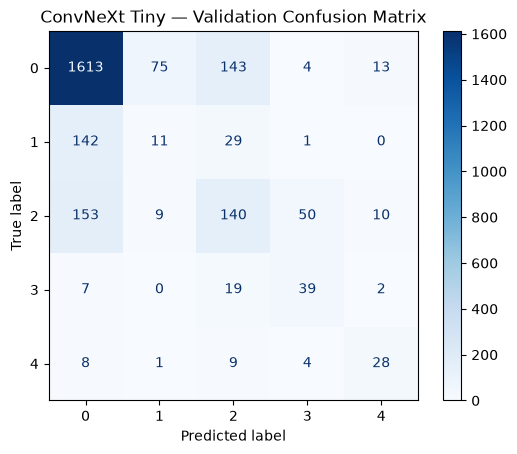

In [43]:
# Cell 33: ConvNeXt validation confusion matrix

convnext_cm = confusion_matrix(
    convnext_y_true,
    convnext_y_pred,
    labels=[0, 1, 2, 3, 4]
)

display(
    pd.DataFrame(
        convnext_cm,
        index=[f"Actual {i}" for i in range(5)],
        columns=[f"Predicted {i}" for i in range(5)]
    )
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=convnext_cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ConvNeXt Tiny — Validation Confusion Matrix")
plt.show()

In [44]:
# Cell 34: Quality-based ConvNeXt evaluation

quality_results = []

for quality_value, quality_name in quality_names.items():

    mask = convnext_qualities == quality_value

    if mask.sum() == 0:
        continue

    true_subset = convnext_y_true[mask]
    pred_subset = convnext_y_pred[mask]

    quality_results.append({
        "Quality": quality_name,
        "Images": int(mask.sum()),
        "Accuracy": accuracy_score(
            true_subset,
            pred_subset
        ),
        "Macro F1": f1_score(
            true_subset,
            pred_subset,
            average="macro",
            zero_division=0
        )
    })

convnext_quality_df = pd.DataFrame(quality_results)

display(convnext_quality_df.round(4))

,Quality,Images,Accuracy,Macro F1
0,Good,1611,0.7486,0.4555
1,Usable,405,0.7235,0.4803
2,Reject,494,0.6721,0.4370


From both experiments on RestNet50 and ConvNext we determine the ffl
1. ResNet50 performs better on Good images.
2. ConvNeXt performs better on Usable images.
3. ConvNeXt also performs slightly better on Reject images.
Both models experience declining performance on Reject images compared with Good images, although the difference is not identical.

Implementing Explanation Stability Aware Trainng 
Architecture         Training Strategy
RestNet50            Standard
RestNet50            Stability - Aware
ConvNext             Standard
ConVNext             Stability - Aware


In stability - We need to introduce two different pair of images 
1. Original Image
2. Degraded Image

Objectives
1. Classification: predict the correct DR grade
2. Explanation Stability: Encourage consistent GRAD - CAM explanations between original and degraded image 

In [45]:
# Cell 35: Controlled retinal image degradation

import torch
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image
import random

class RetinalDegradation:

    def __init__(self, blur_radius=1.5, noise_std=0.03):
        self.blur_radius = blur_radius
        self.noise_std = noise_std

    def __call__(self, image):

        # Apply Gaussian blur
        image = TF.gaussian_blur(
            image,
            kernel_size=[5, 5],
            sigma=self.blur_radius
        )

        # Convert image to tensor
        image = TF.to_tensor(image)

        # Add Gaussian noise
        noise = torch.randn_like(image) * self.noise_std

        image = torch.clamp(image + noise, 0, 1)

        return TF.to_pil_image(image)


degradation_transform = RetinalDegradation(
    blur_radius=1.5,
    noise_std=0.03
)

print("Controlled degradation pipeline created.")

Controlled degradation pipeline created.


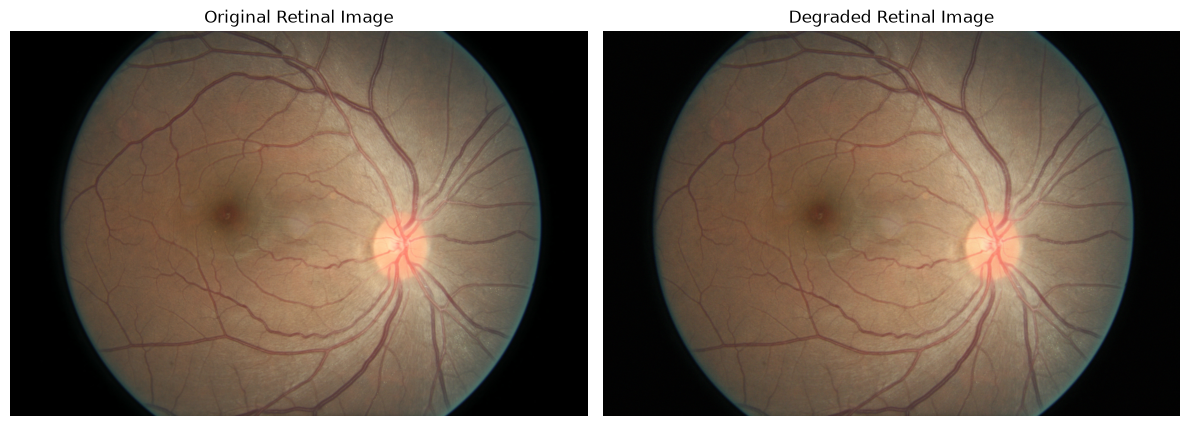

DR grade: 0
EyeQ quality: Good


In [46]:
# Cell 36: Visual inspection of degradation

import matplotlib.pyplot as plt

sample_row = train_df.iloc[0]

original_image = Image.open(
    sample_row["file_path"]
).convert("RGB")

degraded_image = degradation_transform(original_image.copy())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Retinal Image")
axes[0].axis("off")

axes[1].imshow(degraded_image)
axes[1].set_title("Degraded Retinal Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("DR grade:", sample_row["DR_grade"])
print("EyeQ quality:", quality_names[sample_row["quality"]])

Good: DR Grade 0
Usable: DR Grade 0
Reject: DR Grade 3


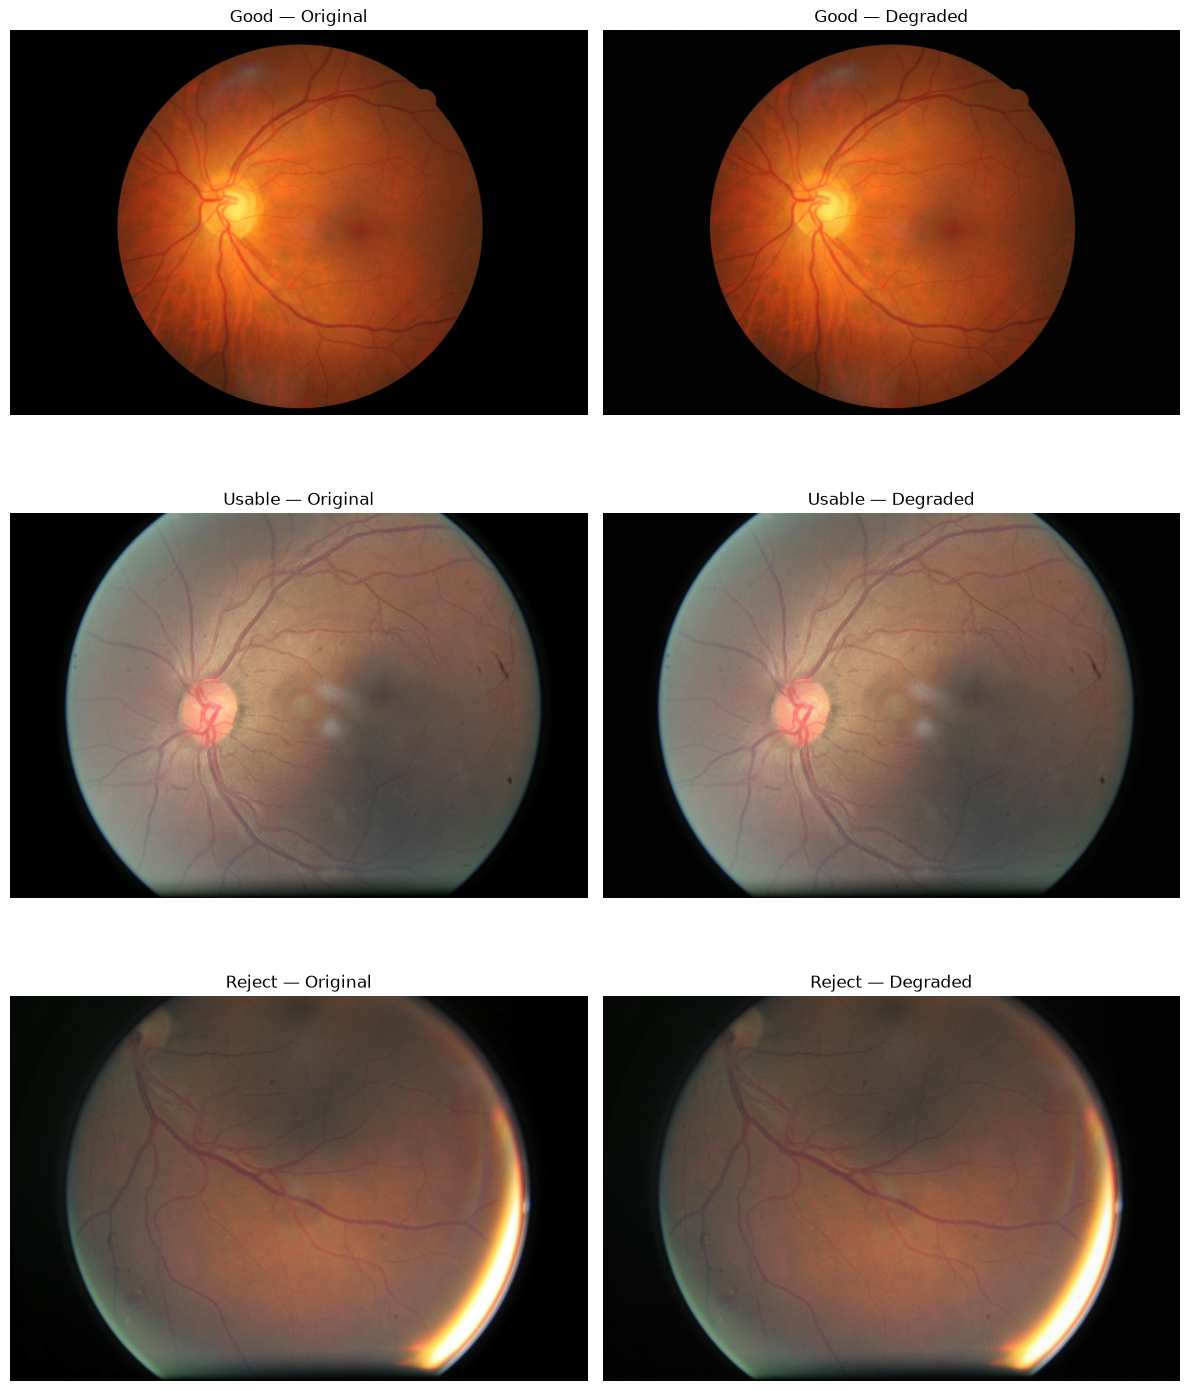

In [47]:
# Cell 37: Test degradation across EyeQ quality categories

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, (quality_value, quality_name) in enumerate(quality_names.items()):

    sample = train_df[
        train_df["quality"] == quality_value
    ].sample(n=1, random_state=42).iloc[0]

    original = Image.open(
        sample["file_path"]
    ).convert("RGB")

    degraded = degradation_transform(original.copy())

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"{quality_name} — Original")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(degraded)
    axes[i, 1].set_title(f"{quality_name} — Degraded")
    axes[i, 1].axis("off")

    print(
        f"{quality_name}: DR Grade {sample['DR_grade']}"
    )

plt.tight_layout()
plt.show()

In [48]:
# Cell 38: Paired original and degraded retinal dataset

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps

class PairedEyeQDataset(Dataset):

    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Load original retinal image
        original = Image.open(
            row["file_path"]
        ).convert("RGB")

        # Apply the same spatial augmentation to both images
        if self.training and random.random() < 0.5:
            original = ImageOps.mirror(original)

        # Generate degraded counterpart
        degraded = degradation_transform(
            original.copy()
        )

        # Apply identical resizing and normalization
        original_tensor = eval_transform(original)
        degraded_tensor = eval_transform(degraded)

        return {
            "original": original_tensor,
            "degraded": degraded_tensor,
            "label": int(row["DR_grade"]),
            "quality": int(row["quality"]),
            "filename": row["image"]
        }


paired_train_dataset = PairedEyeQDataset(
    train_df,
    training=True
)

paired_val_dataset = PairedEyeQDataset(
    val_df,
    training=False
)

paired_train_loader = DataLoader(
    paired_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

paired_val_loader = DataLoader(
    paired_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Paired datasets created successfully.")
print("Training pairs:", len(paired_train_dataset))
print("Validation pairs:", len(paired_val_dataset))

Paired datasets created successfully.
Training pairs: 10033
Validation pairs: 2510


In [49]:
# Cell 39: Verify paired image tensors

paired_batch = next(iter(paired_train_loader))

original_images = paired_batch["original"]
degraded_images = paired_batch["degraded"]
labels = paired_batch["label"]
qualities = paired_batch["quality"]

print("Original images:", original_images.shape)
print("Degraded images:", degraded_images.shape)
print("DR labels:", labels.shape)
print("Quality labels:", qualities.shape)

print("\nDR grades:", labels.tolist())
print("Quality labels:", qualities.tolist())

print(
    "\nOriginal and degraded tensors have matching shapes:",
    original_images.shape == degraded_images.shape
)

Original images: torch.Size([16, 3, 224, 224])
Degraded images: torch.Size([16, 3, 224, 224])
DR labels: torch.Size([16])
Quality labels: torch.Size([16])

DR grades: [0, 4, 0, 0, 0, 0, 4, 2, 0, 0, 2, 0, 1, 0, 0, 0]
Quality labels: [0, 2, 0, 0, 1, 1, 2, 2, 0, 0, 0, 1, 0, 0, 1, 0]

Original and degraded tensors have matching shapes: True


In [50]:
# Cell 40: Reproducible paired retinal dataset

class PairedEyeQDataset(Dataset):

    def __init__(self, dataframe, training=False, seed=2026):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training
        self.seed = seed

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        original = Image.open(
            row["file_path"]
        ).convert("RGB")

        if self.training:
            if random.random() < 0.5:
                original = ImageOps.mirror(original)

            degraded = degradation_transform(
                original.copy()
            )

        else:
            # Use the same random noise for each validation image
            with torch.random.fork_rng(devices=[]):
                torch.manual_seed(self.seed + idx)

                degraded = degradation_transform(
                    original.copy()
                )

        original_tensor = eval_transform(original)
        degraded_tensor = eval_transform(degraded)

        return {
            "original": original_tensor,
            "degraded": degraded_tensor,
            "label": int(row["DR_grade"]),
            "quality": int(row["quality"]),
            "filename": row["image"]
        }


# Recreate datasets
paired_train_dataset = PairedEyeQDataset(
    train_df,
    training=True
)

paired_val_dataset = PairedEyeQDataset(
    val_df,
    training=False
)

paired_train_loader = DataLoader(
    paired_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

paired_val_loader = DataLoader(
    paired_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Updated paired datasets created.")
print("Validation degradation is now reproducible.")

Updated paired datasets created.
Validation degradation is now reproducible.


In [51]:
# Cell 41: Check that validation degradation is reproducible

sample_a = paired_val_dataset[0]
sample_b = paired_val_dataset[0]

same_original = torch.equal(
    sample_a["original"],
    sample_b["original"]
)

same_degraded = torch.equal(
    sample_a["degraded"],
    sample_b["degraded"]
)

print("Original images identical:", same_original)
print("Degraded images identical:", same_degraded)

assert same_original and same_degraded, (
    "Validation images are not reproducible."
)

print("\nReproducibility check passed.")

Original images identical: True
Degraded images identical: True

Reproducibility check passed.


In [52]:
# Cell 42: Inspect Grad-CAM target layers

print("RESNET50 TARGET LAYER")
print(resnet_model.layer4[-1])

print("\nCONVNEXT TINY TARGET LAYER")
print(convnext_model.features[-1])

print("\nResNet50 target:", type(resnet_model.layer4[-1]).__name__)
print("ConvNeXt target:", type(convnext_model.features[-1]).__name__)

RESNET50 TARGET LAYER
Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)

CONVNEXT TINY TARGET LAYER
Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=Tru

In [53]:
# Cell 43: Verify differentiable Grad-CAM for both architectures

import torch.nn.functional as F

def verify_gradcam_gradients(model, target_layer, model_name):

    model = model.to(device)
    model.eval()
    model.zero_grad(set_to_none=True)

    # Use only two paired images for this test
    batch = next(iter(paired_train_loader))

    original = batch["original"][:2].to(device)
    degraded = batch["degraded"][:2].to(device)
    labels = batch["label"][:2].to(device)

    batch_size = original.size(0)

    # Original images first, followed by degraded images
    images = torch.cat([original, degraded], dim=0)
    target_classes = labels.repeat(2)

    activations = []

    def forward_hook(module, inputs, output):
        activations.append(output)

    hook = target_layer.register_forward_hook(forward_hook)

    try:
        with torch.enable_grad():

            logits = model(images)

            feature_maps = activations[0]

            # Select the ground-truth DR class for each image
            scores = logits.gather(
                1,
                target_classes.unsqueeze(1)
            ).sum()

            gradients = torch.autograd.grad(
                outputs=scores,
                inputs=feature_maps,
                create_graph=True,
                retain_graph=True
            )[0]

            # Grad-CAM weights
            weights = gradients.mean(
                dim=(2, 3),
                keepdim=True
            )

            # Generate Grad-CAM maps
            cams = F.relu(
                (weights * feature_maps).sum(
                    dim=1,
                    keepdim=True
                )
            )

            cams = F.interpolate(
                cams,
                size=(224, 224),
                mode="bilinear",
                align_corners=False
            )

            # Normalize each explanation map
            cam_min = cams.amin(
                dim=(2, 3),
                keepdim=True
            )

            cam_max = cams.amax(
                dim=(2, 3),
                keepdim=True
            )

            cams = (
                (cams - cam_min) /
                (cam_max - cam_min + 1e-8)
            )

            original_cams = cams[:batch_size]
            degraded_cams = cams[batch_size:]

            # Explanation consistency loss
            stability_loss = F.mse_loss(
                original_cams,
                degraded_cams
            )

            # Test gradient propagation
            stability_loss.backward()

            gradient_exists = any(
                parameter.grad is not None
                and torch.isfinite(parameter.grad).all()
                and parameter.grad.abs().sum().item() > 0
                for parameter in model.parameters()
            )

            print(f"\n{model_name}")
            print("Feature map shape:", feature_maps.shape)
            print("Grad-CAM shape:", cams.shape)
            print("Stability loss:", stability_loss.item())
            print("Gradient propagation:", gradient_exists)

            assert gradient_exists, (
                f"{model_name}: Grad-CAM loss did not propagate gradients."
            )

            assert torch.isfinite(stability_loss), (
                f"{model_name}: Stability loss is not finite."
            )

            print("Differentiable Grad-CAM check passed.")

    finally:
        hook.remove()
        model.zero_grad(set_to_none=True)
        model.cpu()
        torch.cuda.empty_cache()


# Test ResNet50
verify_gradcam_gradients(
    resnet_model,
    resnet_model.layer4[-1],
    "ResNet50"
)

# Test ConvNeXt Tiny
verify_gradcam_gradients(
    convnext_model,
    convnext_model.features[-1],
    "ConvNeXt Tiny"
)


ResNet50
Feature map shape: torch.Size([4, 2048, 7, 7])
Grad-CAM shape: torch.Size([4, 1, 224, 224])
Stability loss: 0.0006809784681536257
Gradient propagation: True
Differentiable Grad-CAM check passed.

ConvNeXt Tiny
Feature map shape: torch.Size([4, 768, 7, 7])
Grad-CAM shape: torch.Size([4, 1, 224, 224])
Stability loss: 0.0007515365723520517
Gradient propagation: True
Differentiable Grad-CAM check passed.


In [54]:

from pathlib import Path
import torch
import shutil
import hashlib
import json
import zipfile

# Original checkpoint locations
work_dir = Path("./working")

checkpoint_files = {
    "ResNet50": work_dir / "resnet50_standard_best.pth",
    "ConvNeXt Tiny": work_dir / "convnext_tiny_standard_best.pth"
}

# Backup directory
backup_dir = work_dir / "DR_Explanation_Stability" / "checkpoints" / "baseline_backup"
backup_dir.mkdir(parents=True, exist_ok=True)

backup_results = {}

for model_name, source in checkpoint_files.items():

    filename = source.name
    destination = backup_dir / filename

    if source.exists():
        shutil.copy2(source, destination)

    else:
        # Recover from the saved best model state if needed
        state_name = (
            "BEST_RESNET_STATE"
            if model_name == "ResNet50"
            else "BEST_CONVNEXT_STATE"
        )

        state = globals().get(state_name)

        if state is None:
            raise FileNotFoundError(
                f"{filename} and its in-memory best state are unavailable."
            )

        torch.save(state, destination)

    # Verify the backup
    loaded = torch.load(
        destination,
        map_location="cpu",
        weights_only=True
    )

    assert isinstance(loaded, dict) and len(loaded) > 0

    sha256 = hashlib.sha256(destination.read_bytes()).hexdigest()

    backup_results[model_name] = {
        "filename": filename,
        "size_MB": round(destination.stat().st_size / (1024**2), 2),
        "sha256": sha256
    }

# Save baseline experiment metadata
metadata = {
    "ResNet50": {
        "best_epoch": 4,
        "validation_accuracy": 0.6755,
        "validation_macro_f1": 0.471959
    },
    "ConvNeXt Tiny": {
        "best_epoch": 2,
        "validation_accuracy": 0.7319,
        "validation_macro_f1": 0.455836
    },
    "checkpoints": backup_results
}

metadata_path = backup_dir / "baseline_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Create one downloadable archive
zip_path = work_dir / "baseline_checkpoints_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in backup_dir.iterdir():
        z.write(file, arcname=file.name)

print("BASELINE BACKUP VERIFIED")

for name, info in backup_results.items():
    print(f"\n{name}:")
    print("File:", info["filename"])
    print("Size:", info["size_MB"], "MB")
    print("SHA256:", info["sha256"][:16], "...")

print("\nMetadata:", metadata_path)
print("Backup archive:", zip_path)


BASELINE BACKUP VERIFIED

ResNet50:
File: resnet50_standard_best.pth
Size: 90.01 MB
SHA256: 678b177c2087bfeb ...

ConvNeXt Tiny:
File: convnext_tiny_standard_best.pth
Size: 106.2 MB
SHA256: 87274c332298a8ca ...

Metadata: working/DR_Explanation_Stability/checkpoints/baseline_backup/baseline_metadata.json
Backup archive: working/baseline_checkpoints_backup.zip


In [55]:
import pandas as pd

print("Dataframes containing EyeQ annotation columns:\n")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        cols = set(obj.columns)
        if {"quality", "DR_grade"}.issubset(cols):
            print(f"Dataframe: {name}")
            print("Shape:", obj.shape)
            print("\nQuality distribution:")
            print(obj["quality"].value_counts(dropna=False).sort_index())
            print("\nDR grade distribution:")
            print(obj["DR_grade"].value_counts(dropna=False).sort_index())
            print("-" * 45)

Dataframes containing EyeQ annotation columns:

Dataframe: train_labels
Shape: (12543, 3)

Quality distribution:
quality
0    8347
1    1876
2    2320
Name: count, dtype: int64

DR grade distribution:
DR_grade
0    9239
1     911
2    1809
3     333
4     251
Name: count, dtype: int64
---------------------------------------------
Dataframe: test_labels
Shape: (16249, 3)

Quality distribution:
quality
0    8471
1    4558
2    3220
Name: count, dtype: int64

DR grade distribution:
DR_grade
0    11362
1     1398
2     2644
3      448
4      397
Name: count, dtype: int64
---------------------------------------------
Dataframe: df
Shape: (16249, 3)

Quality distribution:
quality
0    8471
1    4558
2    3220
Name: count, dtype: int64

DR grade distribution:
DR_grade
0    11362
1     1398
2     2644
3      448
4      397
Name: count, dtype: int64
---------------------------------------------
Dataframe: eyeq_train
Shape: (12543, 4)

Quality distribution:
quality
0    8347
1    1876
2    2320


In [56]:
# ============================================================
# MAIN EXPERIMENT: CONFIGURATION AND CHECKPOINT VERIFICATION
# ============================================================

from pathlib import Path
import torch

# 1. Experiment configuration
EXPERIMENT_CONFIG = {
    "image_size": 224,
    "batch_size": 16,
    "epochs": 5,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "seeds": [42],
    "strategies": [
        "standard",
        "degradation_aware",
        "stability_aware"
    ],
    "architectures": [
        "ResNet50",
        "ConvNeXt Tiny"
    ]
}

# 2. Device
EXPERIMENT_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 3. Checkpoint locations
CHECKPOINT_DIR = Path(
    "./working/DR_Explanation_Stability/checkpoints"
)

BASELINE_BACKUP_DIR = (
    CHECKPOINT_DIR / "baseline_backup"
)

RESNET_CHECKPOINT = (
    BASELINE_BACKUP_DIR / "resnet50_standard_best.pth"
)

CONVNEXT_CHECKPOINT = (
    BASELINE_BACKUP_DIR / "convnext_tiny_standard_best.pth"
)

# 4. Verify checkpoint compatibility without modifying models
def inspect_checkpoint(path, model, model_name):

    print(f"\nChecking {model_name}...")

    assert path.exists(), f"Checkpoint not found: {path}"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    # Support either a direct state_dict or a nested checkpoint
    if isinstance(checkpoint, dict):
        for key in ["state_dict", "model_state_dict", "model"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    model_state = model.state_dict()

    checkpoint_keys = set(checkpoint.keys())
    model_keys = set(model_state.keys())

    missing = model_keys - checkpoint_keys
    unexpected = checkpoint_keys - model_keys

    shape_mismatches = [
        key for key in model_keys & checkpoint_keys
        if checkpoint[key].shape != model_state[key].shape
    ]

    print("Missing keys:", len(missing))
    print("Unexpected keys:", len(unexpected))
    print("Shape mismatches:", len(shape_mismatches))

    if missing:
        print("Example missing keys:", list(missing)[:5])

    if unexpected:
        print("Example unexpected keys:", list(unexpected)[:5])

    if shape_mismatches:
        print("Example shape mismatches:", shape_mismatches[:5])

    compatible = (
        len(missing) == 0
        and len(unexpected) == 0
        and len(shape_mismatches) == 0
    )

    print("Checkpoint compatible:", compatible)

    assert compatible, (
        f"{model_name} checkpoint is not fully compatible."
    )

    return True


print("=" * 60)
print("MAIN EXPERIMENT CONFIGURATION")
print("=" * 60)

for key, value in EXPERIMENT_CONFIG.items():
    print(f"{key}: {value}")

print("\nDevice:", EXPERIMENT_DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 5. Verify both saved baseline checkpoints
assert "resnet_model" in globals()
assert "convnext_model" in globals()

inspect_checkpoint(
    RESNET_CHECKPOINT,
    resnet_model,
    "ResNet50"
)

inspect_checkpoint(
    CONVNEXT_CHECKPOINT,
    convnext_model,
    "ConvNeXt Tiny"
)

print("\n" + "=" * 60)
print("CONFIGURATION AND CHECKPOINT VERIFICATION COMPLETE")
print("=" * 60)

MAIN EXPERIMENT CONFIGURATION
image_size: 224
batch_size: 16
epochs: 5
learning_rate: 0.0001
weight_decay: 0.0001
seeds: [42]
strategies: ['standard', 'degradation_aware', 'stability_aware']
architectures: ['ResNet50', 'ConvNeXt Tiny']

Device: cuda
GPU: AMD Radeon RX 6600

Checking ResNet50...
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0
Checkpoint compatible: True

Checking ConvNeXt Tiny...
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0
Checkpoint compatible: True

CONFIGURATION AND CHECKPOINT VERIFICATION COMPLETE


In [57]:
# ============================================================
# STEP 2A: LOAD COMMON BASELINE WEIGHTS
# ============================================================

import copy
import torch

EXPERIMENT_BASELINE_STATES = {}

checkpoint_paths = {
    "ResNet50": RESNET_CHECKPOINT,
    "ConvNeXt Tiny": CONVNEXT_CHECKPOINT
}

for model_name, checkpoint_path in checkpoint_paths.items():

    state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # Keep an independent copy of the saved weights
    EXPERIMENT_BASELINE_STATES[model_name] = {
        key: value.detach().cpu().clone()
        for key, value in state.items()
    }

    print(f"\n{model_name}")
    print("Parameters loaded:", len(state))
    print(
        "Total parameter tensors:",
        len(EXPERIMENT_BASELINE_STATES[model_name])
    )

# Verify that the preserved weights match the checkpoints
for model_name, checkpoint_path in checkpoint_paths.items():

    saved_state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    for key, value in saved_state.items():
        assert torch.equal(
            value,
            EXPERIMENT_BASELINE_STATES[model_name][key]
        )

print("\nCommon baseline weights loaded and verified.")
print("Original checkpoint files remain unchanged.")


ResNet50
Parameters loaded: 320
Total parameter tensors: 320

ConvNeXt Tiny
Parameters loaded: 182
Total parameter tensors: 182

Common baseline weights loaded and verified.
Original checkpoint files remain unchanged.


In [58]:
# ============================================================
# STEP 2B: FRESH MODEL INITIALIZATION
# ============================================================

import copy
import gc
import torch

# Existing architecture templates
MODEL_TEMPLATES = {
    "ResNet50": resnet_model,
    "ConvNeXt Tiny": convnext_model
}

def create_experiment_model(model_name, device=EXPERIMENT_DEVICE):

    if model_name not in MODEL_TEMPLATES:
        raise ValueError(f"Unknown architecture: {model_name}")

    # Create an independent model instance
    model = copy.deepcopy(MODEL_TEMPLATES[model_name])

    # Load the verified common baseline weights
    model.load_state_dict(
        EXPERIMENT_BASELINE_STATES[model_name],
        strict=True
    )

    model = model.to(device)

    return model


# Verify fresh initialization for both architectures
for model_name in MODEL_TEMPLATES:

    print(f"\nTesting {model_name}...")

    test_model = create_experiment_model(model_name)

    # Confirm every parameter matches the saved baseline
    for key, value in test_model.state_dict().items():

        expected = EXPERIMENT_BASELINE_STATES[model_name][key]

        assert torch.equal(
            value.detach().cpu(),
            expected
        ), f"Weight mismatch: {key}"

    print("Fresh model created successfully.")
    print("All weights match the baseline checkpoint.")

    # Release GPU memory before testing the next architecture
    del test_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nFresh model initialization verified.")


Testing ResNet50...
Fresh model created successfully.
All weights match the baseline checkpoint.

Testing ConvNeXt Tiny...
Fresh model created successfully.
All weights match the baseline checkpoint.

Fresh model initialization verified.


In [59]:
# ============================================================
# STEP 3: INSPECT CURRENT DEGRADATION PIPELINE
# ============================================================

import inspect

print("=" * 60)
print("DEGRADATION TRANSFORM")
print("=" * 60)

print("Object:", degradation_transform)
print("Type:", type(degradation_transform))

try:
    print("\nImplementation:")
    print(inspect.getsource(type(degradation_transform)))
except (OSError, TypeError):
    print("Source unavailable for this object.")

print("\n" + "=" * 60)
print("PAIRED DATASET CONFIGURATION")
print("=" * 60)

print("Training pairs:", len(paired_train_dataset))
print("Validation pairs:", len(paired_val_dataset))

print("Training mode:", paired_train_dataset.training)
print("Validation mode:", paired_val_dataset.training)

print("\nImage size:", EXPERIMENT_CONFIG["image_size"])
print("Batch size:", EXPERIMENT_CONFIG["batch_size"])

print("\nInspection complete.")

DEGRADATION TRANSFORM
Object: <__main__.RetinalDegradation object at 0x735a11cc9070>
Type: <class '__main__.RetinalDegradation'>

Implementation:
Source unavailable for this object.

PAIRED DATASET CONFIGURATION
Training pairs: 10033
Validation pairs: 2510
Training mode: True
Validation mode: False

Image size: 224
Batch size: 16

Inspection complete.


In [60]:
# ============================================================
# STEP 3A: INSPECT RETINAL DEGRADATION PARAMETERS
# ============================================================

import inspect

print("=" * 60)
print("DEGRADATION CLASS PARAMETERS")
print("=" * 60)

# Inspect instance attributes
print("\nInstance attributes:")
print(vars(degradation_transform))

# Inspect available methods
print("\nClass methods:")
for name, method in inspect.getmembers(
    type(degradation_transform),
    predicate=inspect.isfunction
):
    print(f"\n{name}")

    try:
        print(inspect.getsource(method))
    except (OSError, TypeError):
        print("Source unavailable.")

# Inspect one actual image pair
sample = paired_val_dataset[0]

original = sample["original"]
degraded = sample["degraded"]

print("\n" + "=" * 60)
print("ACTUAL IMAGE PAIR")
print("=" * 60)

print("Filename:", sample["filename"])
print("DR grade:", sample["label"])
print("Quality:", sample["quality"])
print("Original shape:", original.shape)
print("Degraded shape:", degraded.shape)
print("Original pixel range:",
      original.min().item(), original.max().item())
print("Degraded pixel range:",
      degraded.min().item(), degraded.max().item())

print("\nDegradation inspection complete.")

DEGRADATION CLASS PARAMETERS

Instance attributes:
{'blur_radius': 1.5, 'noise_std': 0.03}

Class methods:

__call__
    def __call__(self, image):

        # Apply Gaussian blur
        image = TF.gaussian_blur(
            image,
            kernel_size=[5, 5],
            sigma=self.blur_radius
        )

        # Convert image to tensor
        image = TF.to_tensor(image)

        # Add Gaussian noise
        noise = torch.randn_like(image) * self.noise_std

        image = torch.clamp(image + noise, 0, 1)

        return TF.to_pil_image(image)


__init__
    def __init__(self, blur_radius=1.5, noise_std=0.03):
        self.blur_radius = blur_radius
        self.noise_std = noise_std


ACTUAL IMAGE PAIR
Filename: 10022_right.jpeg
DR grade: 0
Quality: 0
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Original pixel range: -2.1179039478302 2.3760502338409424
Degraded pixel range: -2.0836544036865234 2.341036319732666

Degradation inspection comple

In [61]:
# ============================================================
# STEP 3B: CONTROLLED RETINAL IMAGE DEGRADATION
# ============================================================

import random
import torch
from PIL import Image, ImageFilter
from torchvision.transforms import functional as TF

DEGRADATION_CONFIG = {
    "mild": {
        "blur_radius": 0.75,
        "noise_std": 0.01
    },
    "moderate": {
        "blur_radius": 1.50,
        "noise_std": 0.03
    },
    "severe": {
        "blur_radius": 2.50,
        "noise_std": 0.06
    }
}


class ControlledRetinalDegradation:

    def __init__(self, level="moderate"):

        if level not in DEGRADATION_CONFIG:
            raise ValueError(f"Unknown degradation level: {level}")

        self.level = level
        self.blur_radius = DEGRADATION_CONFIG[level]["blur_radius"]
        self.noise_std = DEGRADATION_CONFIG[level]["noise_std"]

    def __call__(self, image):

        # Apply Gaussian blur to the PIL image
        blurred = image.filter(
            ImageFilter.GaussianBlur(
                radius=self.blur_radius
            )
        )

        # Convert to [0, 1] tensor
        tensor = TF.to_tensor(blurred)

        # Add Gaussian noise before normalization
        noise = torch.randn_like(tensor) * self.noise_std

        degraded = torch.clamp(
            tensor + noise,
            min=0.0,
            max=1.0
        )

        return TF.to_pil_image(degraded)


# Create one transform for each degradation level
degradation_transforms = {
    level: ControlledRetinalDegradation(level)
    for level in DEGRADATION_CONFIG
}


print("Controlled degradation transforms created:")

for level, config in DEGRADATION_CONFIG.items():
    print(
        f"{level.capitalize()}: "
        f"blur={config['blur_radius']}, "
        f"noise={config['noise_std']}"
    )


# Test all levels using one validation image
sample_path = val_df.iloc[0]["file_path"]

sample_image = Image.open(
    sample_path
).convert("RGB")

print("\nTesting degradation output:")

for level, transform in degradation_transforms.items():

    torch.manual_seed(42)

    degraded_image = transform(sample_image.copy())

    raw_tensor = TF.to_tensor(degraded_image)

    print(
        f"{level.capitalize()}: "
        f"size={degraded_image.size}, "
        f"range=({raw_tensor.min().item():.4f}, "
        f"{raw_tensor.max().item():.4f})"
    )

    assert degraded_image.size == sample_image.size
    assert torch.isfinite(raw_tensor).all()

print("\nControlled degradation tests passed.")

Controlled degradation transforms created:
Mild: blur=0.75, noise=0.01
Moderate: blur=1.5, noise=0.03
Severe: blur=2.5, noise=0.06

Testing degradation output:
Mild: size=(3888, 2592), range=(0.0000, 1.0000)
Moderate: size=(3888, 2592), range=(0.0000, 1.0000)
Severe: size=(3888, 2592), range=(0.0000, 1.0000)

Controlled degradation tests passed.


In [62]:
# ============================================================
# STEP 3C: CONTROLLED PAIRED EYEQ DATASET
# ============================================================

import random
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps


class ControlledPairedEyeQDataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=False,
        level=None,
        seed=2026
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training
        self.level = level
        self.seed = seed

        if not training and level not in DEGRADATION_CONFIG:
            raise ValueError(
                "Validation requires a valid degradation level."
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        original = Image.open(
            row["file_path"]
        ).convert("RGB")

        # Use deterministic per-image randomness
        local_rng = random.Random(self.seed + idx)

        if self.training:
            selected_level = local_rng.choice(
                list(DEGRADATION_CONFIG.keys())
            )
        else:
            selected_level = self.level

        # Apply the same horizontal flip to both images
        if self.training and local_rng.random() < 0.5:
            original = ImageOps.mirror(original)

        # Make degradation reproducible for this image
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(self.seed + idx)

            degraded = degradation_transforms[
                selected_level
            ](original.copy())

        original_tensor = eval_transform(original)
        degraded_tensor = eval_transform(degraded)

        return {
            "original": original_tensor,
            "degraded": degraded_tensor,
            "label": int(row["DR_grade"]),
            "quality": int(row["quality"]),
            "filename": row["image"],
            "level": selected_level
        }


# Training dataset: includes all three degradation levels
controlled_train_dataset = ControlledPairedEyeQDataset(
    train_df,
    training=True,
    seed=2026
)

controlled_train_loader = DataLoader(
    controlled_train_dataset,
    batch_size=EXPERIMENT_CONFIG["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=True
)


# Separate validation datasets for each severity
controlled_val_datasets = {}
controlled_val_loaders = {}

for level in DEGRADATION_CONFIG:

    dataset = ControlledPairedEyeQDataset(
        val_df,
        training=False,
        level=level,
        seed=2026
    )

    controlled_val_datasets[level] = dataset

    controlled_val_loaders[level] = DataLoader(
        dataset,
        batch_size=EXPERIMENT_CONFIG["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )


print("Controlled paired datasets created.")
print("Training pairs:", len(controlled_train_dataset))

for level, dataset in controlled_val_datasets.items():
    print(f"{level.capitalize()} validation pairs:", len(dataset))

Controlled paired datasets created.
Training pairs: 10033
Mild validation pairs: 2510
Moderate validation pairs: 2510
Severe validation pairs: 2510


In [63]:
# ============================================================
# STEP 3D: VERIFY CONTROLLED PAIRED DATASET
# ============================================================

batch = next(iter(controlled_train_loader))

print("TRAINING BATCH")
print("Original:", batch["original"].shape)
print("Degraded:", batch["degraded"].shape)
print("DR labels:", batch["label"].shape)
print("Quality labels:", batch["quality"].shape)
print("Degradation levels:", batch["level"])

assert batch["original"].shape == batch["degraded"].shape
assert batch["original"].shape[1:] == (3, 224, 224)

# Verify all three validation levels
print("\nVALIDATION REPRODUCIBILITY")

for level, dataset in controlled_val_datasets.items():

    sample_a = dataset[0]
    sample_b = dataset[0]

    assert torch.equal(
        sample_a["original"],
        sample_b["original"]
    )

    assert torch.equal(
        sample_a["degraded"],
        sample_b["degraded"]
    )

    assert sample_a["level"] == level

    print(f"{level.capitalize()}: reproducibility passed")

print("\nAll controlled dataset checks passed.")

TRAINING BATCH
Original: torch.Size([16, 3, 224, 224])
Degraded: torch.Size([16, 3, 224, 224])
DR labels: torch.Size([16])
Quality labels: torch.Size([16])
Degradation levels: ['moderate', 'mild', 'severe', 'severe', 'severe', 'moderate', 'severe', 'moderate', 'moderate', 'severe', 'moderate', 'moderate', 'moderate', 'severe', 'severe', 'moderate']

VALIDATION REPRODUCIBILITY
Mild: reproducibility passed
Moderate: reproducibility passed
Severe: reproducibility passed

All controlled dataset checks passed.


In [65]:
# ============================================================
# STEP 4A: AUDIT EXISTING TRAINING COMPONENTS
# ============================================================

print("AVAILABLE DATASETS AND LOADERS")
for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["dataset", "loader"]):
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

print("\nAVAILABLE MODEL OBJECTS")
for name, obj in globals().copy().items():
    if isinstance(obj, torch.nn.Module):
        print(f"{name}: {type(obj).__name__}")

print("\nGRAD-CAM AND LOSS FUNCTIONS")
for name, obj in globals().copy().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["grad", "cam", "loss", "criterion"]
    ):
        print(f"{name}: {type(obj).__name__}")

print("\nEXISTING TRAINING FUNCTIONS")
for name, obj in globals().copy().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["train", "evaluate", "validate"]
    ):
        print(f"{name}: {type(obj).__name__}")

AVAILABLE DATASETS AND LOADERS
Dataset: type
DataLoader: type
EyeQDataset: type
train_dataset: EyeQDataset
val_dataset: EyeQDataset
test_dataset: EyeQDataset
train_loader: DataLoader
val_loader: DataLoader
test_loader: DataLoader
PairedEyeQDataset: type
paired_train_dataset: PairedEyeQDataset
paired_val_dataset: PairedEyeQDataset
paired_train_loader: DataLoader
paired_val_loader: DataLoader
ControlledPairedEyeQDataset: type
controlled_train_dataset: ControlledPairedEyeQDataset
controlled_train_loader: DataLoader
controlled_val_datasets: dict
controlled_val_loaders: dict
dataset: ControlledPairedEyeQDataset

AVAILABLE MODEL OBJECTS
resnet_model: ResNet
convnext_model: ConvNeXt
criterion: CrossEntropyLoss

GRAD-CAM AND LOSS FUNCTIONS
criterion: CrossEntropyLoss
RetinalDegradation: type
degradation_transform: RetinalDegradation
verify_gradcam_gradients: function
ControlledRetinalDegradation: type

EXISTING TRAINING FUNCTIONS
train_transform: Compose
train_one_epoch: function
evaluate_mode

In [66]:
import inspect

print("=" * 60)
print("TRAINING FUNCTION SIGNATURES")
print("=" * 60)

print("\ntrain_one_epoch:")
print(inspect.signature(train_one_epoch))

print("\nevaluate_model:")
print(inspect.signature(evaluate_model))

print("\n" + "=" * 60)
print("TRAINING FUNCTION SOURCE")
print("=" * 60)

print("\ntrain_one_epoch source:")
print(inspect.getsource(train_one_epoch))

print("\nevaluate_model source:")
print(inspect.getsource(evaluate_model))

TRAINING FUNCTION SIGNATURES

train_one_epoch:
(model, loader, optimizer, criterion, scaler)

evaluate_model:
(model, loader, criterion)

TRAINING FUNCTION SOURCE

train_one_epoch source:
def train_one_epoch(model, loader, optimizer, criterion, scaler):

    model.train()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for batch in tqdm(loader, desc="Training", leave=False):

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.exte

In [67]:
import dis

print("=" * 60)
print("TRAIN_ONE_EPOCH: INTERNAL OPERATIONS")
print("=" * 60)
print("Variables:", train_one_epoch.__code__.co_varnames)
print("Referenced operations:", train_one_epoch.__code__.co_names)
dis.dis(train_one_epoch)

print("\n" + "=" * 60)
print("EVALUATE_MODEL: INTERNAL OPERATIONS")
print("=" * 60)
print("Variables:", evaluate_model.__code__.co_varnames)
print("Referenced operations:", evaluate_model.__code__.co_names)
dis.dis(evaluate_model)

TRAIN_ONE_EPOCH: INTERNAL OPERATIONS
Variables: ('model', 'loader', 'optimizer', 'criterion', 'scaler', 'running_loss', 'all_predictions', 'all_labels', 'batch', 'images', 'labels', 'outputs', 'loss', 'predictions', 'epoch_loss', 'epoch_accuracy', 'epoch_f1')
Referenced operations: ('train', 'tqdm', 'to', 'device', 'zero_grad', 'torch', 'autocast', 'float16', 'scale', 'backward', 'step', 'update', 'item', 'size', 'argmax', 'extend', 'cpu', 'numpy', 'len', 'dataset', 'accuracy_score', 'f1_score')
  3           0 RESUME                   0

  5           2 LOAD_FAST                0 (model)
              4 LOAD_ATTR                1 (NULL|self + train)
             24 CALL                     0
             32 POP_TOP

  7          34 LOAD_CONST               1 (0.0)
             36 STORE_FAST               5 (running_loss)

  8          38 BUILD_LIST               0
             40 STORE_FAST               6 (all_predictions)

  9          42 BUILD_LIST               0
             44 S

In [68]:
print("CONTROLLED TRAINING BATCH")
batch = next(iter(controlled_train_loader))

for key, value in batch.items():
    if torch.is_tensor(value):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{key}: {value[:5]}")

print("\nMODEL DEVICE")
print("ResNet50:", next(resnet_model.parameters()).device)
print("ConvNeXt:", next(convnext_model.parameters()).device)

print("\nGRAD-CAM FUNCTION SIGNATURE")
print(inspect.signature(verify_gradcam_gradients))

CONTROLLED TRAINING BATCH
original: shape=torch.Size([16, 3, 224, 224]), dtype=torch.float32
degraded: shape=torch.Size([16, 3, 224, 224]), dtype=torch.float32
label: shape=torch.Size([16]), dtype=torch.int64
quality: shape=torch.Size([16]), dtype=torch.int64
filename: ['38723_left.jpeg', '6403_left.jpeg', '13959_left.jpeg', '18556_right.jpeg', '21297_left.jpeg']
level: ['severe', 'severe', 'mild', 'severe', 'severe']

MODEL DEVICE
ResNet50: cpu
ConvNeXt: cpu

GRAD-CAM FUNCTION SIGNATURE
(model, target_layer, model_name)


In [69]:
import inspect

print("=" * 60)
print("AVAILABLE GRAD-CAM / STABILITY FUNCTIONS")
print("=" * 60)

for name, obj in globals().copy().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["gradcam", "grad_cam", "cam", "stability"]
    ):
        try:
            print(f"\n{name}{inspect.signature(obj)}")
        except (TypeError, ValueError):
            print(f"\n{name}: callable")

print("\n" + "=" * 60)
print("MODEL TARGET LAYERS")
print("=" * 60)

print("ResNet50 final convolutional layer:")
print(resnet_model.layer4[-1])

print("\nConvNeXt Tiny final feature block:")
print(convnext_model.features[-1])

AVAILABLE GRAD-CAM / STABILITY FUNCTIONS

verify_gradcam_gradients(model, target_layer, model_name)

MODEL TARGET LAYERS
ResNet50 final convolutional layer:
Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)

ConvNeXt Tiny final feature block:
Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in

In [70]:
import torch
import torch.nn.functional as F
import gc

def differentiable_gradcam(model, images, target_layer, labels):
    """
    Grad-CAM that preserves gradients through the CAM calculation.
    Target class: ground-truth DR grade.
    """
    activations = {}

    def forward_hook(module, inputs, output):
        activations["features"] = output

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        logits = model(images)
        features = activations["features"]

        target_scores = logits.gather(
            1, labels.view(-1, 1)
        ).sum()

        gradients = torch.autograd.grad(
            outputs=target_scores,
            inputs=features,
            create_graph=True,
            retain_graph=True
        )[0]

        weights = gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = F.relu(
            (weights * features).sum(dim=1, keepdim=True)
        )

        cam = F.interpolate(
            cam,
            size=images.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam / (
            cam.amax(dim=(2, 3), keepdim=True) + 1e-8
        )

        return cam, logits

    finally:
        handle.remove()


# ------------------------------------------------------------
# TEST DIFFERENTIABLE GRAD-CAM ON A SMALL BATCH
# ------------------------------------------------------------

device = EXPERIMENT_DEVICE

test_batch = next(iter(controlled_train_loader))

original = test_batch["original"][:2].to(device)
degraded = test_batch["degraded"][:2].to(device)
labels = test_batch["label"][:2].to(device)

target_layers = {
    "ResNet50": lambda model: model.layer4[-1],
    "ConvNeXt Tiny": lambda model: model.features[-1]
}

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    print(f"\nTesting {model_name}")

    model = create_experiment_model(model_name)
    model.eval()
    model.zero_grad(set_to_none=True)

    cam_original, logits_original = differentiable_gradcam(
        model, original, target_layers[model_name](model), labels
    )

    cam_degraded, logits_degraded = differentiable_gradcam(
        model, degraded, target_layers[model_name](model), labels
    )

    stability_loss = F.mse_loss(
        cam_original, cam_degraded
    )

    model.zero_grad(set_to_none=True)
    stability_loss.backward()

    gradient_norm = sum(
        parameter.grad.detach().norm().item()
        for parameter in model.parameters()
        if parameter.grad is not None
    )

    print("Original CAM:", cam_original.shape)
    print("Degraded CAM:", cam_degraded.shape)
    print("Stability loss:", stability_loss.item())
    print("Gradient norm:", gradient_norm)

    assert cam_original.shape == cam_degraded.shape
    assert torch.isfinite(stability_loss)
    assert gradient_norm > 0

    print("Differentiable Grad-CAM test: PASSED")

    del model, cam_original, cam_degraded
    del logits_original, logits_degraded
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll differentiable Grad-CAM tests passed.")


Testing ResNet50
Original CAM: torch.Size([2, 1, 224, 224])
Degraded CAM: torch.Size([2, 1, 224, 224])
Stability loss: 0.0006240867078304291
Gradient norm: 1.4739515685723745
Differentiable Grad-CAM test: PASSED

Testing ConvNeXt Tiny
Original CAM: torch.Size([2, 1, 224, 224])
Degraded CAM: torch.Size([2, 1, 224, 224])
Stability loss: 0.000153699133079499
Gradient norm: 0.292053555250277
Differentiable Grad-CAM test: PASSED

All differentiable Grad-CAM tests passed.
